# Modelling, part 3: regularised linear models

**Goal of this notebook.** Train Ridge, Lasso and Elastic Net to predict the business digitalisation index, evaluate them with the same country-grouped cross-validation used for the baselines, and see which variables they rely on.

**The question that matters.** Do these models beat **baseline B (mean by year)** from the previous notebook? If they do not, the explanatory variables add little beyond the common time trend, and that is a result worth reporting honestly.

**Contents**
0. Setup
1. Loading data and baselines
2. Step 1: the pipeline (and why it prevents leakage)
3. Step 2: the three models with fixed hyperparameters
4. Step 3: choosing the hyperparameters with nested cross-validation
5. Step 4: reading the coefficients (and how stable they are)
6. Step 5: results table and charts
7. Checklist before moving on

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = next((p for p in [Path(".."), Path(".")] if (p / "data" / "processed").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Cannot find data/processed: open the project from its root folder.")

FIG_DIR = ROOT / "outputs" / "figures"
TAB_DIR = ROOT / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

RANDOM_STATE = 42

## 1. Loading data and baselines

`FEATURES` is the same list defined in notebook 02. We also load the baseline results saved in notebook 03, so that every comparison uses the same numbers.

In [2]:
FEATURES = ["skills_basic", "skills_above", "ict_specialists", "fttp", "vhcn", "gbit5g",
            "log_gdp_pc_ppp", "tertiary_enrol", "rnd_gdp", "urban_pop"]

df = pd.read_csv(ROOT / "data" / "processed" / "model_data.csv")
y = df["business_index"].to_numpy()
groups = df["country"].to_numpy()
X = df[FEATURES]

baseline_path = TAB_DIR / "baseline_results.csv"
if not baseline_path.exists():
    raise FileNotFoundError("Run notebook 03 first: outputs/tables/baseline_results.csv is missing.")
baselines = pd.read_csv(baseline_path)

print("Rows:", len(df), "| Countries:", df["country"].nunique(), "| Features:", len(FEATURES))
print("Missing values in features:", int(X.isna().sum().sum()))
display(baselines.round(3))

Rows: 81 | Countries: 27 | Features: 10
Missing values in features: 0


,model,cv,R2,RMSE,MAE
0,Baseline A: training mean,GroupKFold(5),-0.158,0.910,0.726
1,Baseline B: mean by year,GroupKFold(5),0.038,0.830,0.644
2,Baseline A: training mean,Leave-one-country-out,-0.060,0.871,0.695
3,Baseline B: mean by year,Leave-one-country-out,0.135,0.787,0.598


## 2. Step 1: the pipeline (and why it prevents leakage)

**Why regularised linear models?** With 81 observations and 10 correlated variables, an ordinary linear regression would overfit. Regularisation adds a penalty on large coefficients:

| Model | Penalty | Effect |
|---|---|---|
| **Ridge** | sum of squared coefficients (L2) | shrinks all coefficients, keeps all variables |
| **Lasso** | sum of absolute coefficients (L1) | can shrink some coefficients exactly to zero (variable selection) |
| **Elastic Net** | mix of both (`l1_ratio`) | compromise; handles groups of correlated variables better than Lasso |

The strength of the penalty is the hyperparameter **alpha** (bigger alpha = simpler model).

**Why standardise?** The penalty treats all coefficients alike, so variables must be on the same scale (otherwise "% of population" and "log GDP" would be penalised differently for no good reason).

**Why a pipeline?** The mean and standard deviation used to standardise (and the median used to fill missing values) must be computed **on the training countries only**. If we standardised the full dataset first, information from the test countries would leak into the training step. A `Pipeline` re-fits imputer and scaler inside every fold automatically.

In [3]:
def make_pipeline(model):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model),
    ])

# Proof that the scaler only sees the training countries of each fold
gkf = GroupKFold(n_splits=5)
tr, te = next(gkf.split(X, y, groups))
pipe = make_pipeline(Ridge(alpha=1.0)).fit(X.iloc[tr], y[tr])

print("Mean of 'skills_basic' used by the scaler in fold 1 :", round(pipe.named_steps["scaler"].mean_[0], 3))
print("Mean of 'skills_basic' on ALL data (not what we use):", round(X["skills_basic"].mean(), 3))
print("Mean on the training rows of fold 1, computed by hand:", round(X.iloc[tr]["skills_basic"].mean(), 3))
assert np.isclose(pipe.named_steps["scaler"].mean_[0], X.iloc[tr]["skills_basic"].mean())
assert set(groups[tr]).isdisjoint(groups[te])

Mean of 'skills_basic' used by the scaler in fold 1 : 58.539
Mean of 'skills_basic' on ALL data (not what we use): 58.31
Mean on the training rows of fold 1, computed by hand: 58.539


The scaler's mean equals the mean of the **training rows** only, and differs from the mean of the whole dataset. That is exactly what prevents leakage.

## 3. Step 2: the three models with fixed hyperparameters

First a quick look with reasonable, *untuned* values, to see the order of magnitude of the results. We use the same helper as in notebook 03 and the same `GroupKFold(5)`, so folds are identical to those of the baselines.

We try two sets of inputs:

- **features only**: the 10 structural variables;
- **features + year**: the same plus the survey year (a number). The target rises over time, so this lets the model capture the common trend, like baseline B does. It is the fairest comparison with baseline B.

In [4]:
def cv_evaluate(model, X, y, groups, splitter):
    """Country-grouped CV. Returns (per-fold table, pooled metrics, out-of-fold predictions)."""
    oof = np.full(len(y), np.nan)
    rows = []
    for k, (tr, te) in enumerate(splitter.split(X, y, groups), start=1):
        m = clone(model).fit(X.iloc[tr], y[tr])
        pred = m.predict(X.iloc[te])
        oof[te] = pred
        rows.append({"fold": k, "R2": r2_score(y[te], pred),
                     "RMSE": np.sqrt(mean_squared_error(y[te], pred)),
                     "MAE": mean_absolute_error(y[te], pred)})
    assert not np.isnan(oof).any()
    pooled = {"R2": r2_score(y, oof), "RMSE": np.sqrt(mean_squared_error(y, oof)),
              "MAE": mean_absolute_error(y, oof)}
    return pd.DataFrame(rows).set_index("fold"), pooled, oof


X_year = df[FEATURES + ["year"]]
fixed_models = {
    "Ridge (alpha=1)": Ridge(alpha=1.0),
    "Lasso (alpha=0.1)": Lasso(alpha=0.1, max_iter=50_000),
    "Elastic Net (alpha=0.1, l1=0.5)": ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=50_000),
}

rows = []
for inputs_name, Xin in [("features only", X), ("features + year", X_year)]:
    for name, model in fixed_models.items():
        _, pooled, _ = cv_evaluate(make_pipeline(model), Xin, y, groups, GroupKFold(n_splits=5))
        rows.append({"model": name, "inputs": inputs_name, **pooled})
fixed_results = pd.DataFrame(rows)
display(fixed_results.round(3))

,model,inputs,R2,RMSE,MAE
0,Ridge (alpha=1),features only,0.528,0.581,0.480
1,Lasso (alpha=0.1),features only,0.573,0.553,0.444
2,"Elastic Net (alpha=0.1, l1=0.5)",features only,0.618,0.523,0.421
3,Ridge (alpha=1),features + year,0.607,0.530,0.422
4,Lasso (alpha=0.1),features + year,0.612,0.527,0.419
5,"Elastic Net (alpha=0.1, l1=0.5)",features + year,0.640,0.507,0.405


**How to read it.** Compare the R² and RMSE with baseline B under `GroupKFold(5)` (the second row of the baseline table above). These alphas were picked by hand, so treat the numbers as a first impression only. Next we choose alpha properly.

## 4. Step 3: choosing the hyperparameters with nested cross-validation

**The trap.** If we try many alphas and report the best score from the same cross-validation, the result is optimistic: we selected the winner on the very data used to judge it.

**The fix: nested CV.**
- **Outer loop** (`GroupKFold(5)`): holds out some countries, used *only* to measure performance.
- **Inner loop** (`GroupKFold(4)` on the remaining countries): chooses alpha (and `l1_ratio`).

The held-out countries never influence the choice of alpha. The inner loop is also grouped by country, otherwise years of the same country would leak between inner train and inner validation.

In [5]:
search_spaces = {
    "Ridge": (Ridge(), {"model__alpha": np.logspace(-2, 3, 30)}),
    "Lasso": (Lasso(max_iter=50_000), {"model__alpha": np.logspace(-3, 0.5, 30)}),
    "Elastic Net": (ElasticNet(max_iter=50_000),
                    {"model__alpha": np.logspace(-3, 0.5, 20), "model__l1_ratio": [0.2, 0.5, 0.8]}),
}


def nested_cv(model, grid, X, y, groups, outer_splits=5, inner_splits=4):
    """Nested country-grouped CV. Returns per-fold table, pooled metrics, OOF predictions and per-fold coefficients."""
    oof = np.full(len(y), np.nan)
    rows, coefs = [], []
    for k, (tr, te) in enumerate(GroupKFold(n_splits=outer_splits).split(X, y, groups), start=1):
        search = GridSearchCV(make_pipeline(model), grid, cv=GroupKFold(n_splits=inner_splits),
                              scoring="neg_root_mean_squared_error")
        search.fit(X.iloc[tr], y[tr], groups=groups[tr])
        pred = search.predict(X.iloc[te])
        oof[te] = pred
        rows.append({"fold": k, "R2": r2_score(y[te], pred),
                     "RMSE": np.sqrt(mean_squared_error(y[te], pred)),
                     "MAE": mean_absolute_error(y[te], pred),
                     **{key.split("__")[1]: val for key, val in search.best_params_.items()}})
        coefs.append(search.best_estimator_.named_steps["model"].coef_)
    assert not np.isnan(oof).any()
    pooled = {"R2": r2_score(y, oof), "RMSE": np.sqrt(mean_squared_error(y, oof)),
              "MAE": mean_absolute_error(y, oof)}
    coef_df = pd.DataFrame(coefs, columns=X.columns, index=pd.RangeIndex(1, outer_splits + 1, name="fold"))
    return pd.DataFrame(rows).set_index("fold"), pooled, oof, coef_df

In [6]:
nested = {}   # (model name, inputs) -> (per-fold, pooled, oof, coefs)
for inputs_name, Xin in [("features only", X), ("features + year", X_year)]:
    for name, (model, grid) in search_spaces.items():
        nested[(name, inputs_name)] = nested_cv(model, grid, Xin, y, groups)

summary = pd.DataFrame(
    [{"model": name, "inputs": inp, **res[1]} for (name, inp), res in nested.items()]
)
display(summary.round(3))

,model,inputs,R2,RMSE,MAE
0,Ridge,features only,0.655,0.497,0.404
1,Lasso,features only,0.581,0.548,0.440
2,Elastic Net,features only,0.631,0.514,0.418
3,Ridge,features + year,0.687,0.473,0.382
4,Lasso,features + year,0.626,0.517,0.413
5,Elastic Net,features + year,0.648,0.502,0.400


In [7]:
# The alpha chosen in each outer fold: if it jumps around, the choice is unstable
for (name, inp), (per_fold, _, _, _) in nested.items():
    if inp == "features + year":
        print(name)
        display(per_fold.round(3))

Ridge


,R2,RMSE,MAE,alpha
fold,,,,
1,0.681,0.521,0.413,28.072
2,0.572,0.457,0.379,41.753
3,0.338,0.464,0.369,28.072
4,0.588,0.377,0.326,28.072
5,0.424,0.523,0.418,41.753


Lasso


,R2,RMSE,MAE,alpha
fold,,,,
1,0.671,0.529,0.418,0.049
2,0.464,0.511,0.412,0.016
3,0.065,0.551,0.421,0.037
4,0.408,0.452,0.383,0.009
5,0.394,0.537,0.429,0.016


Elastic Net


,R2,RMSE,MAE,alpha,l1_ratio
fold,,,,,
1,0.639,0.554,0.436,0.248,0.2
2,0.565,0.461,0.373,0.379,0.2
3,0.232,0.499,0.387,0.248,0.2
4,0.432,0.442,0.378,0.030,0.8
5,0.390,0.539,0.422,0.162,0.2


**What to look at.**

- Pooled R² / RMSE of each model versus **baseline B** (same `GroupKFold(5)` folds).
- Whether adding `year` helps. If "features + year" is clearly better than "features only", part of the signal was simply the time trend.
- Whether the chosen alpha is stable across folds. Strong variation means the data cannot pin the penalty down, which is normal with 81 rows.
- Per-fold R² is noisy (5–6 countries per fold): do not over-read a single fold.

## 5. Step 4: reading the coefficients (and how stable they are)

Because the inputs are standardised, a coefficient is the change in the index for **one standard deviation** of that variable, holding the others fixed. Coefficients are therefore comparable in size across variables.

We use the coefficients of the models fitted in each of the 5 outer folds (each trained on a different set of countries). This shows **how stable** they are: a variable whose sign flips or that is often exactly zero is not reliably associated with the target.

*Remember: these are associations, not causal effects, and with correlated variables the effect is shared among them in an arbitrary way.*

In [8]:
CHOSEN_INPUTS = "features + year"      # change to "features only" to compare

coef_summary = {}
for name in ["Ridge", "Lasso", "Elastic Net"]:
    c = nested[(name, CHOSEN_INPUTS)][3]
    coef_summary[name] = pd.DataFrame({
        "mean": c.mean(),
        "std": c.std(),
        "folds_nonzero": (c.abs() > 1e-8).sum(),
        "folds_same_sign": c.apply(lambda s: max((s > 0).sum(), (s < 0).sum())),
    })

for name, t in coef_summary.items():
    print(f"\n{name} - coefficients across the 5 outer folds ({CHOSEN_INPUTS})")
    display(t.sort_values("mean", key=abs, ascending=False).round(3))


Ridge - coefficients across the 5 outer folds (features + year)


,mean,std,folds_nonzero,folds_same_sign
skills_above,0.150,0.028,5,5
year,0.140,0.018,5,5
rnd_gdp,0.138,0.020,5,5
skills_basic,0.119,0.016,5,5
ict_specialists,0.106,0.026,5,5
urban_pop,0.104,0.039,5,5
vhcn,0.076,0.026,5,5
log_gdp_pc_ppp,0.075,0.029,5,5
gbit5g,0.068,0.019,5,5
tertiary_enrol,0.052,0.010,5,5



Lasso - coefficients across the 5 outer folds (features + year)


,mean,std,folds_nonzero,folds_same_sign
skills_above,0.289,0.107,5,5
year,0.236,0.036,5,5
rnd_gdp,0.173,0.055,5,5
urban_pop,0.127,0.081,4,4
ict_specialists,0.108,0.076,4,4
vhcn,0.064,0.084,3,3
log_gdp_pc_ppp,0.042,0.076,5,5
skills_basic,0.029,0.087,2,1
tertiary_enrol,0.029,0.032,3,3
fttp,-0.023,0.044,2,2



Elastic Net - coefficients across the 5 outer folds (features + year)


,mean,std,folds_nonzero,folds_same_sign
skills_above,0.208,0.083,5,5
year,0.177,0.051,5,5
rnd_gdp,0.153,0.055,5,5
urban_pop,0.117,0.066,5,5
ict_specialists,0.095,0.066,4,4
skills_basic,0.088,0.056,4,4
gbit5g,0.043,0.029,4,4
log_gdp_pc_ppp,0.043,0.046,5,5
vhcn,0.039,0.034,5,5
tertiary_enrol,0.007,0.009,2,2


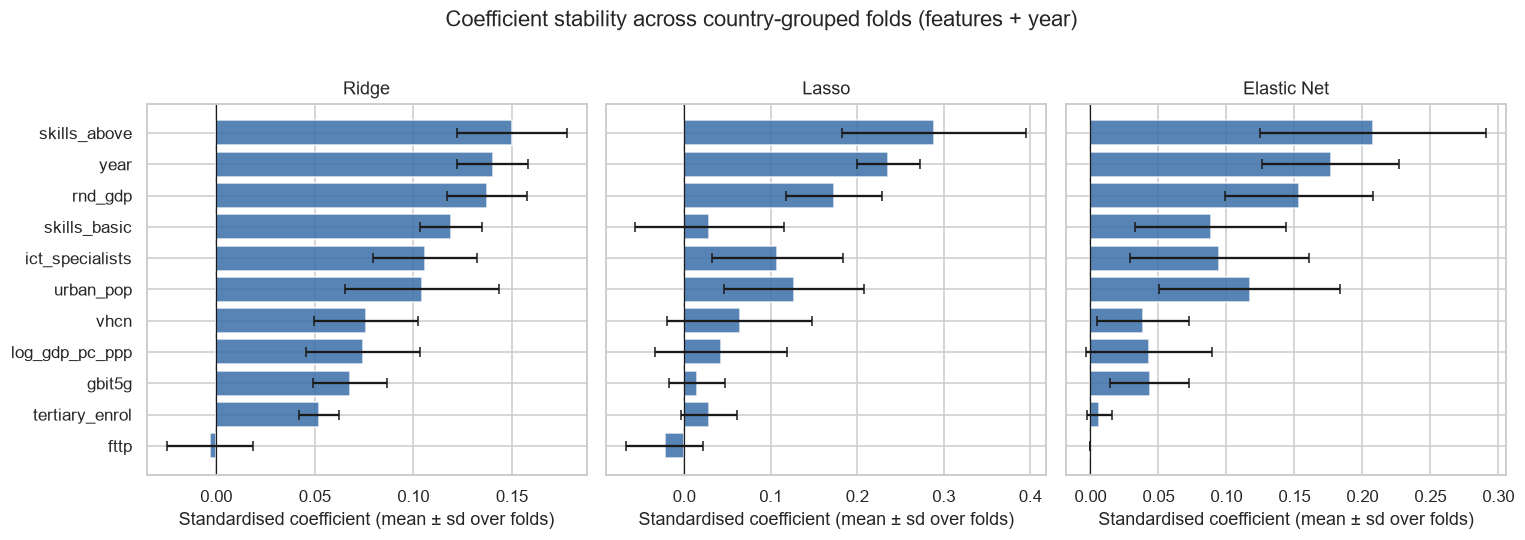

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharey=True)
order = coef_summary["Ridge"]["mean"].abs().sort_values().index
for ax, (name, t) in zip(axes, coef_summary.items()):
    t = t.loc[order]
    ax.barh(t.index, t["mean"], xerr=t["std"], color="#3b6ea8", alpha=0.85, capsize=3)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(name)
    ax.set_xlabel("Standardised coefficient (mean ± sd over folds)")
fig.suptitle(f"Coefficient stability across country-grouped folds ({CHOSEN_INPUTS})", y=1.02)
plt.tight_layout()
save_fig("10_linear_coefficients")
plt.show()

**How to read the chart.** Bars far from zero with short error lines are the stable associations. Bars whose error line crosses zero are unreliable. Compare the three panels: Lasso typically sets some coefficients to exactly zero, and which ones it drops among correlated variables (skills, GDP, tertiary education, R&D) can change from fold to fold.

### What I noticed
All three regularised linear models clearly beat the benchmarks under nested country-grouped cross-validation. With features and year, Ridge reaches R² = 0.69 and RMSE = 0.47, against R² = 0.04 and RMSE = 0.83 for the mean-by-year baseline, so the structural variables explain a large share of the differences between countries, well beyond the common time trend. Ridge is the best model, followed by Elastic Net (R² = 0.65) and Lasso (R² = 0.63), but with only 27 countries these gaps are small and should not be over-interpreted. Adding the year improves every model by a few hundredths of R² (Ridge goes from 0.66 to 0.69), so most of the signal comes from the structural variables and not from the trend. The coefficient chart shows that skills_above, year and rnd_gdp are consistently large and positive, while fttp, tertiary_enrol, gbit5g and log_gdp_pc_ppp are small or unstable. Lasso and Elastic Net shrink skills_basic towards zero while keeping skills_above, which suggests that the two skill variables are strongly correlated and carry overlapping information. In the predicted-versus-actual plot, points lie along the diagonal and spread horizontally, but the highest-scoring observations (2025) are underestimated, as expected from regularised models that pull predictions towards the mean.

## 6. Step 5: results table and charts

In [10]:
base_gkf = baselines[baselines["cv"] == "GroupKFold(5)"].rename(columns={"model": "model"})
base_rows = pd.DataFrame({
    "model": base_gkf["model"],
    "inputs": ["none", "year only"] if len(base_gkf) == 2 else "n/a",
    "R2": base_gkf["R2"].values, "RMSE": base_gkf["RMSE"].values, "MAE": base_gkf["MAE"].values,
})

all_results = pd.concat([base_rows, summary.assign(model=lambda d: d["model"] + " (nested CV)")], ignore_index=True)
all_results = all_results[["model", "inputs", "R2", "RMSE", "MAE"]]
display(all_results.round(3))
all_results.round(4).to_csv(TAB_DIR / "model_results.csv", index=False)
print("Saved to", TAB_DIR / "model_results.csv")

,model,inputs,R2,RMSE,MAE
0,Baseline A: training mean,none,-0.158,0.910,0.726
1,Baseline B: mean by year,year only,0.038,0.830,0.644
2,Ridge (nested CV),features only,0.655,0.497,0.404
3,Lasso (nested CV),features only,0.581,0.548,0.440
4,Elastic Net (nested CV),features only,0.631,0.514,0.418
5,Ridge (nested CV),features + year,0.687,0.473,0.382
6,Lasso (nested CV),features + year,0.626,0.517,0.413
7,Elastic Net (nested CV),features + year,0.648,0.502,0.400


Saved to ..\outputs\tables\model_results.csv


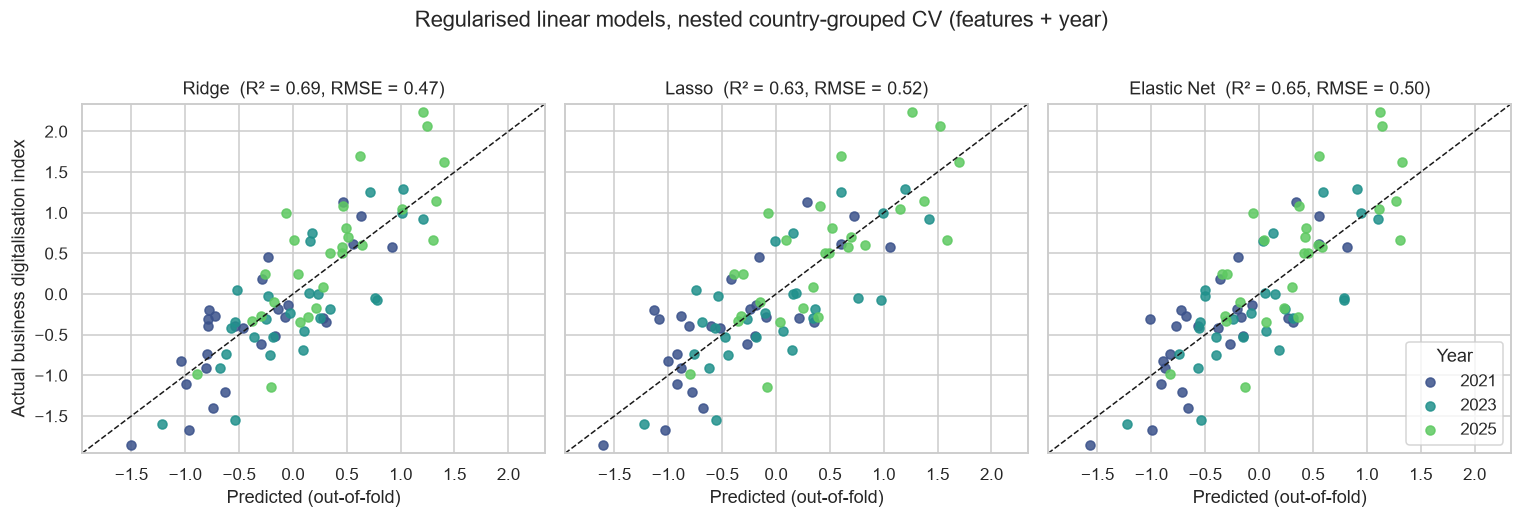

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharex=True, sharey=True)
lims = (y.min() - 0.1, y.max() + 0.1)
palette = dict(zip(sorted(df["year"].unique()), sns.color_palette("viridis", df["year"].nunique())))

for ax, name in zip(axes, ["Ridge", "Lasso", "Elastic Net"]):
    _, pooled, oof, _ = nested[(name, CHOSEN_INPUTS)]
    for yr, g in df.groupby("year"):
        ax.scatter(oof[g.index], y[g.index], s=35, alpha=0.85, color=palette[yr], label=str(yr))
    ax.plot(lims, lims, "k--", lw=1)
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_title(f"{name}  (R² = {pooled['R2']:.2f}, RMSE = {pooled['RMSE']:.2f})")
    ax.set_xlabel("Predicted (out-of-fold)")
axes[0].set_ylabel("Actual business digitalisation index")
axes[2].legend(title="Year", loc="lower right")
fig.suptitle(f"Regularised linear models, nested country-grouped CV ({CHOSEN_INPUTS})", y=1.02)
plt.tight_layout()
save_fig("11_linear_predictions")
plt.show()

**How to read the chart.** Compare with the baseline chart (`09_baseline_predictions.png`). If the models are useful, the points move towards the dashed diagonal and spread *horizontally* (the model tells countries apart), not just by colour. Look for countries far from the diagonal: those are the ones the structural variables cannot explain.

## 7. Checklist before moving on

- [ ] I can explain why standardisation must happen inside the pipeline.
- [ ] I can explain the difference between Ridge, Lasso and Elastic Net.
- [ ] I can explain why nested CV is needed to choose alpha honestly.
- [ ] I know whether each model beats **baseline B** and by how much.
- [ ] I know which coefficients are stable across folds and which are not.
- [ ] `outputs/tables/model_results.csv`, `10_linear_coefficients.png` and `11_linear_predictions.png` exist.

**Next notebook (`05_models_nonlinear.ipynb`)**: Random Forest and Gradient Boosting, permutation importance and SHAP, compared with the models above.